# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Kadek Nathania Gavrila Astika | 5054251050 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [38]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
RANDOM_STATE = 42

INCOME = "Annual Income (k$)"
SPEND = "Spending Score (1-100)"

In [39]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
df = pd.read_csv("Mall_Customers.csv")
display(df.head())

# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.
print("Jumlah baris, kolom :", df.shape)
print("\nTipe data:")
print(df.dtypes)
print("\nStatistik deskriptif:")
display(df.describe(include="all"))
print("Jumlah missing value per kolom:")
print(df.isna().sum())
print("\nJumlah baris duplikat:", df.duplicated().sum())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Jumlah baris, kolom : (200, 5)

Tipe data:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Statistik deskriptif:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
count,200.000,200,200.000,200.000,200.000
unique,NaN,2,NaN,NaN,NaN
top,NaN,Female,NaN,NaN,NaN
freq,NaN,112,NaN,NaN,NaN
mean,100.500,NaN,38.850,60.560,50.200
std,57.879,NaN,13.969,26.265,25.824
min,1.000,NaN,18.000,15.000,1.000
25%,50.750,NaN,28.750,41.500,34.750
50%,100.500,NaN,36.000,61.500,50.000
75%,150.250,NaN,49.000,78.000,73.000


Jumlah missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat: 0


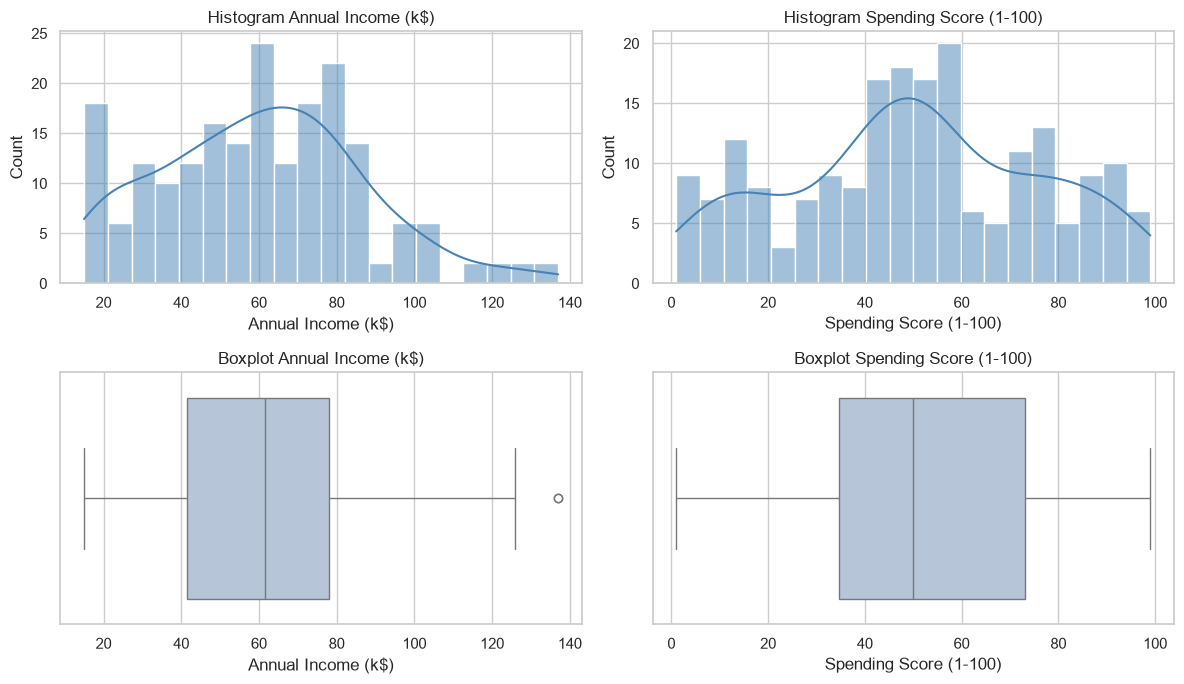

Annual Income (k$): rentang 15-137, skewness 0.322, batas IQR [-13.2, 132.8], jumlah outlier = 2
   nilai outlier: [137, 137]
Spending Score (1-100): rentang 1-99, skewness -0.047, batas IQR [-22.6, 130.4], jumlah outlier = 0


In [40]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, col in enumerate([INCOME, SPEND]):
    sns.histplot(df[col], bins=20, kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"Histogram {col}")
    sns.boxplot(x=df[col], ax=axes[1, i], color="lightsteelblue")
    axes[1, i].set_title(f"Boxplot {col}")
plt.tight_layout()
plt.show()

# Deteksi outlier dengan aturan IQR (1.5 x IQR)
for col in [INCOME, SPEND]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df[(df[col] < low) | (df[col] > high)]
    print(f"{col}: rentang {df[col].min()}-{df[col].max()}, skewness {df[col].skew():.3f}, "
          f"batas IQR [{low:.1f}, {high:.1f}], jumlah outlier = {len(outliers)}")
    if len(outliers):
        print("   nilai outlier:", outliers[col].tolist())

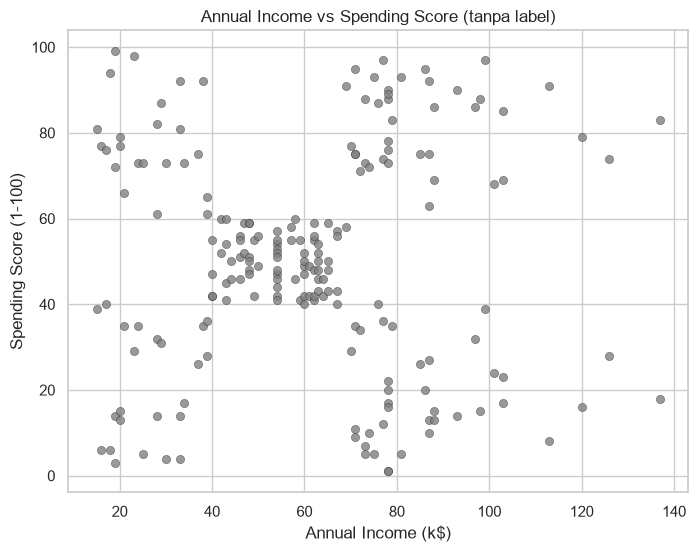

In [41]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.
plt.figure(figsize=(8, 6))
plt.scatter(df[INCOME], df[SPEND], s=35, color="gray", alpha=0.8, edgecolor="k", linewidth=0.3)
plt.title("Annual Income vs Spending Score (tanpa label)")
plt.xlabel(INCOME)
plt.ylabel(SPEND)
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat? **Tidak ada missing value maupun baris duplikat**
- Bagaimana rentang pendapatan dan spending score? **Annual Income (k$) berada pada rentang 15–137, sedangkan Spending Score (1-100) berada pada rentang 1–99**
- Apakah kedua fitur tampak memiliki kelompok yang terpisah? **Ya, terlihat sekitar lima kelompok pelanggan berdasarkan kombinasi pendapatan dan spending score**

# 2. Preprocessing

In [42]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.
print("Missing value sebelum:", df.isna().sum().sum(), "| Duplikat sebelum:", df.duplicated().sum())
df = df.dropna().drop_duplicates().reset_index(drop=True)   # tidak mengubah apa pun pada data ini
print("Ukuran data setelah dibersihkan:", df.shape)

X = df[[INCOME, SPEND]].copy()
display(X.head())
print("Ukuran X:", X.shape)

Missing value sebelum: 0 | Duplikat sebelum: 0
Ukuran data setelah dibersihkan: (200, 5)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


Ukuran X: (200, 2)


In [43]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)                      
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

display(X_scaled_df.head())
display(X_scaled_df.describe())

,Annual Income (k$),Spending Score (1-100)
0,-1.739,-0.435
1,-1.739,1.196
2,-1.701,-1.716
3,-1.701,1.040
4,-1.663,-0.396


,Annual Income (k$),Spending Score (1-100)
count,200.000,200.000
mean,-0.000,-0.000
std,1.003,1.003
min,-1.739,-1.910
25%,-0.728,-0.600
50%,0.036,-0.008
75%,0.666,0.885
max,2.918,1.894


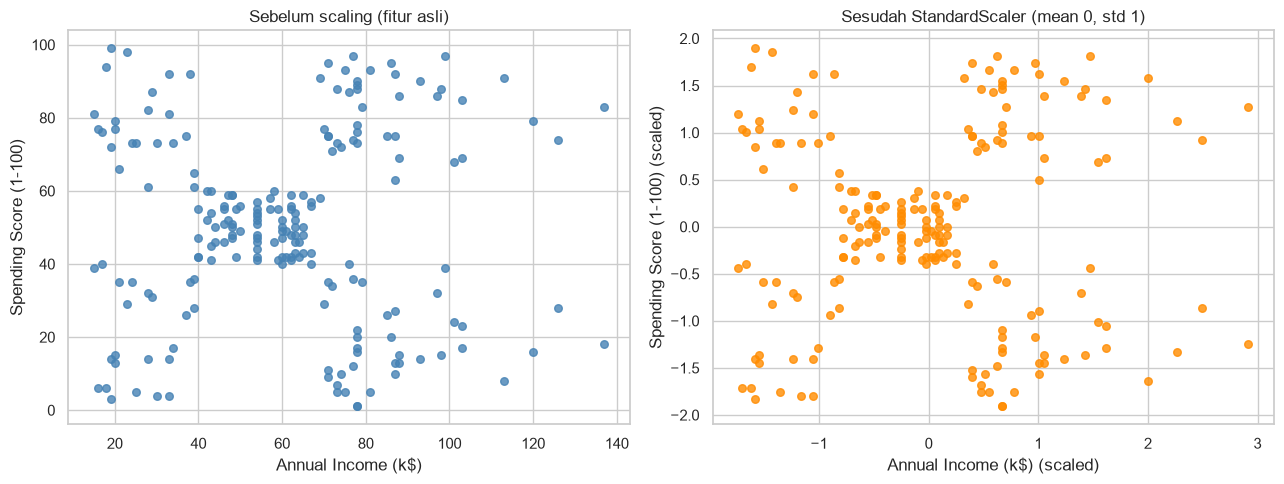

In [44]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X[INCOME], X[SPEND], s=30, color="steelblue", alpha=0.8)
axes[0].set_title("Sebelum scaling (fitur asli)")
axes[0].set_xlabel(INCOME); axes[0].set_ylabel(SPEND)

axes[1].scatter(X_scaled_df[INCOME], X_scaled_df[SPEND], s=30, color="darkorange", alpha=0.8)
axes[1].set_title("Sesudah StandardScaler (mean 0, std 1)")
axes[1].set_xlabel(INCOME + " (scaled)"); axes[1].set_ylabel(SPEND + " (scaled)")
plt.tight_layout()
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Jawab:** Alasan pemilihan Annual Income dan Spending Score digunakan yaitu kedua fitur ini menggambarkan dua hal yang paling relevan untuk segmentasi pelanggan mal seperti kemampuan membeli (pendapatan) dan perilaku atau kecenderungan membeli (spending score). Kedua fitur tersebut numerik dan kontinu sehingga cocok untuk algoritma berbasis jarak dan densitas. CostumerID tidak digunakan karena CostumerID hanya berperan sebagai nomor urut atau identitas saja.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

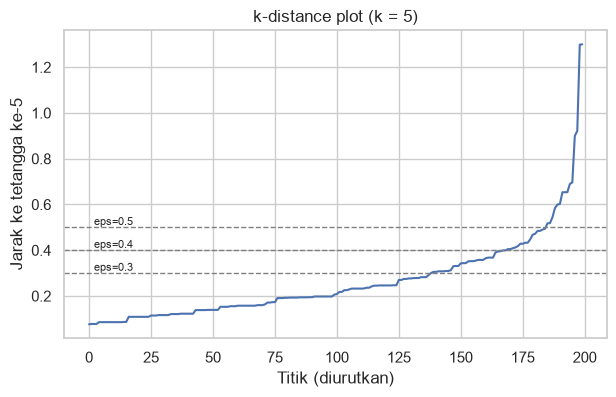

In [45]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.
k = 5
nn = NearestNeighbors(n_neighbors=k).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])
plt.figure(figsize=(7, 4))
plt.plot(k_dist)
for e in [0.3, 0.4, 0.5]:
    plt.axhline(e, ls="--", lw=1, color="gray")
    plt.text(2, e + 0.01, f"eps={e}", fontsize=8)
plt.title(f"k-distance plot (k = {k})")
plt.xlabel("Titik (diurutkan)")
plt.ylabel(f"Jarak ke tetangga ke-{k}")
plt.show()

# Model awal sesuai instruksi
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

In [46]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).
def ringkas_dbscan(labels):
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    return n_clusters, n_noise

print("Jumlah anggota per label (eps=0.3, min_samples=5):")
print(pd.Series(labels_dbscan).value_counts().sort_index())
n_cl, n_noise = ringkas_dbscan(labels_dbscan)
print(f"\nJumlah cluster (tanpa noise): {n_cl}")
print(f"Jumlah titik noise (-1)    : {n_noise} ({n_noise / len(labels_dbscan):.1%})")

Jumlah anggota per label (eps=0.3, min_samples=5):
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

Jumlah cluster (tanpa noise): 7
Jumlah titik noise (-1)    : 35 (17.5%)


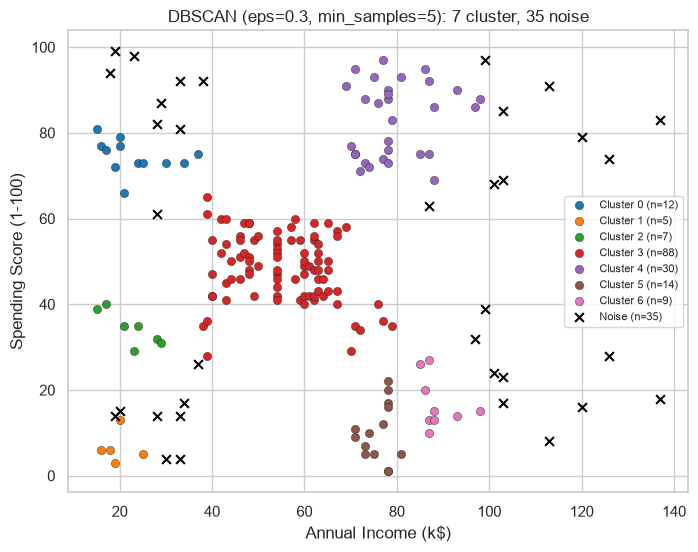

In [47]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.
def plot_clusters(labels, title, ax=None):
    """Scatter plot pada fitur asli X; label -1 digambar sebagai noise (x hitam)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    labels = np.asarray(labels)
    uniq = sorted(l for l in set(labels) if l != -1)
    palette = sns.color_palette("tab10", max(len(uniq), 1))
    for color, lab in zip(palette, uniq):
        m = labels == lab
        ax.scatter(X.loc[m, INCOME], X.loc[m, SPEND], s=35, color=color,
                   edgecolor="k", linewidth=0.3, label=f"Cluster {lab} (n={m.sum()})")
    if -1 in labels:
        m = labels == -1
        ax.scatter(X.loc[m, INCOME], X.loc[m, SPEND], s=40, color="black",
                   marker="x", label=f"Noise (n={m.sum()})")
    ax.set_title(title)
    ax.set_xlabel(INCOME)
    ax.set_ylabel(SPEND)
    ax.legend(fontsize=8, loc="best")
    return ax

plot_clusters(labels_dbscan, f"DBSCAN (eps=0.3, min_samples=5): {n_cl} cluster, {n_noise} noise")
plt.show()

,eps,min_samples,n_clusters,n_noise,noise_%,silhouette (non-noise)
0,0.200,3,13,44,22.000,0.470
1,0.200,5,7,77,38.500,0.586
2,0.200,8,2,116,58.000,0.603
3,0.200,10,1,129,64.500,NaN
4,0.300,3,9,14,7.000,0.472
5,0.300,5,7,35,17.500,0.524
6,0.300,8,5,72,36.000,0.593
7,0.300,10,4,88,44.000,0.607
8,0.400,3,4,10,5.000,0.395
9,0.400,5,4,15,7.500,0.478


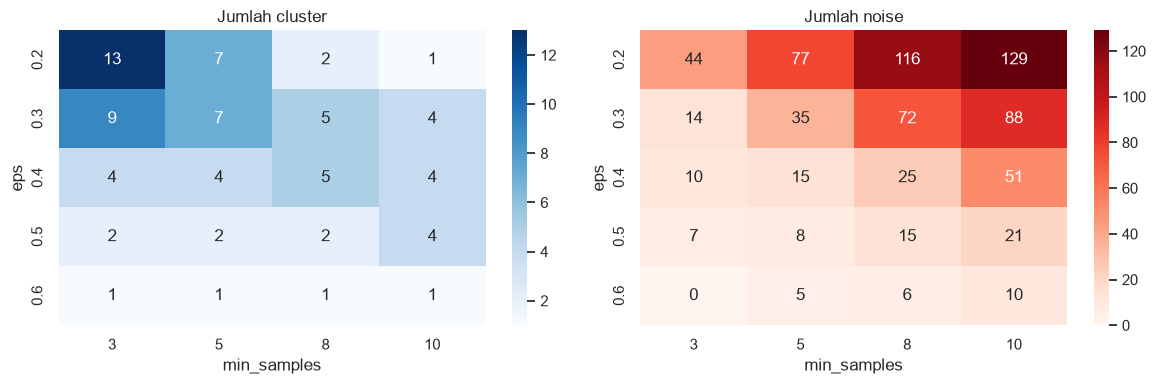

Parameter DBSCAN terpilih: eps=0.4, min_samples=8 -> 5 cluster, 25 noise, silhouette=0.549


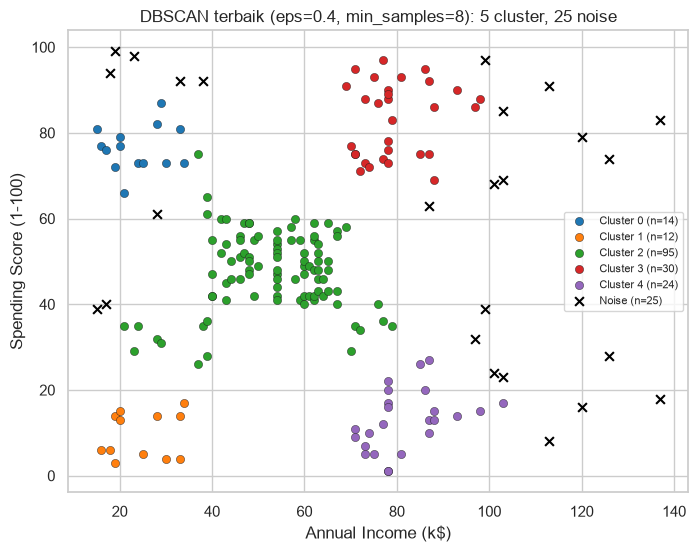

In [48]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.
rows = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for ms in [3, 5, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl, n_noise = ringkas_dbscan(lab)
        mask = lab != -1
        sil = (silhouette_score(X_scaled[mask], lab[mask])
               if n_cl >= 2 and n_cl < mask.sum() else np.nan)
        rows.append({"eps": eps, "min_samples": ms, "n_clusters": n_cl,
                     "n_noise": n_noise, "noise_%": 100 * n_noise / len(lab),
                     "silhouette (non-noise)": sil})
dbscan_grid = pd.DataFrame(rows)
display(dbscan_grid)

# Heatmap jumlah cluster dan noise untuk melihat pola
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(dbscan_grid.pivot(index="eps", columns="min_samples", values="n_clusters"),
            annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Jumlah cluster")
sns.heatmap(dbscan_grid.pivot(index="eps", columns="min_samples", values="n_noise"),
            annot=True, fmt="d", cmap="Reds", ax=axes[1])
axes[1].set_title("Jumlah noise")
plt.tight_layout()
plt.show()

# Pemilihan parameter terbaik:
# silhouette pada titik non-noise cenderung "naik palsu" jika banyak titik dibuang
# sebagai noise, sehingga dibatasi noise <= 15% data, lalu dipilih silhouette tertinggi.
kandidat = dbscan_grid[(dbscan_grid["noise_%"] <= 15) & dbscan_grid["silhouette (non-noise)"].notna()]
best_db = kandidat.sort_values("silhouette (non-noise)", ascending=False).iloc[0]
BEST_EPS, BEST_MS = float(best_db["eps"]), int(best_db["min_samples"])
print(f"Parameter DBSCAN terpilih: eps={BEST_EPS}, min_samples={BEST_MS} "
      f"-> {int(best_db['n_clusters'])} cluster, {int(best_db['n_noise'])} noise, "
      f"silhouette={best_db['silhouette (non-noise)']:.3f}")

labels_dbscan_best = DBSCAN(eps=BEST_EPS, min_samples=BEST_MS).fit_predict(X_scaled)
n_cl_b, n_noise_b = ringkas_dbscan(labels_dbscan_best)
plot_clusters(labels_dbscan_best,
              f"DBSCAN terbaik (eps={BEST_EPS}, min_samples={BEST_MS}): {n_cl_b} cluster, {n_noise_b} noise")
plt.show()

### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise? **Semakin besar nilai eps, jumlah cluster cenderung berkurang karena cluster kecil bergabung, sedangkan jumlah noise semakin menurun**
- Apa pengaruh `min_samples`? **Semakin besar nilai min_samples, semakin ketat syarat kepadatan sehingga jumlah noise meningkat dan jumlah cluster cenderung berkurang**
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise? **Ada, eps=0.6 menghasilkan satu cluster besar, sedangkan eps=0.2 dan min_samples=10 menghasilkan 129 noise (64,5%)**

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [49]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)
print("Jumlah subcluster (leaf CF entries) yang terbentuk:", len(birch.subcluster_centers_))

Jumlah subcluster (leaf CF entries) yang terbentuk: 10


In [50]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.
print("Jumlah anggota per cluster BIRCH (threshold=0.5, n_clusters=5):")
print(pd.Series(labels_birch).value_counts().sort_index())
print("\nJumlah cluster yang terbentuk:", len(np.unique(labels_birch)))
print(f"Silhouette Score: {silhouette_score(X_scaled, labels_birch):.3f}")

Jumlah anggota per cluster BIRCH (threshold=0.5, n_clusters=5):
0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64

Jumlah cluster yang terbentuk: 5
Silhouette Score: 0.414


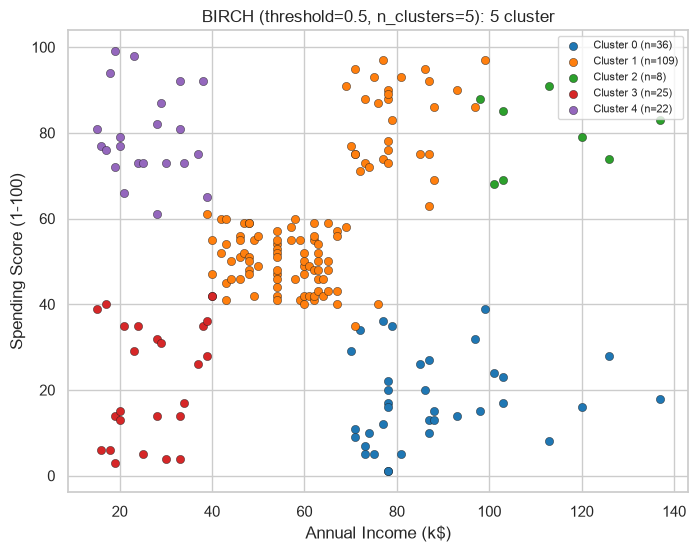

In [51]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.
plot_clusters(labels_birch, f"BIRCH (threshold=0.5, n_clusters=5): {len(np.unique(labels_birch))} cluster")
plt.show()

,threshold,n_clusters (param),n_subcluster,n_cluster akhir,ukuran cluster,silhouette
0,0.200,5,39,5,"[85, 39, 32, 23, 21]",0.554
1,0.200,None,39,39,-,0.401
2,0.300,5,23,5,"[101, 38, 36, 22, 3]",0.478
3,0.300,None,23,23,-,0.414
4,0.350,5,18,5,"[81, 39, 36, 23, 21]",0.555
5,0.350,None,18,18,-,0.398
6,0.400,5,15,5,"[76, 39, 38, 26, 21]",0.537
7,0.400,None,15,15,-,0.414
8,0.500,5,10,5,"[109, 36, 25, 22, 8]",0.414
9,0.500,None,10,10,"[78, 31, 26, 22, 13, 12, 8, 6, 2, 2]",0.477


Threshold BIRCH terpilih: 0.35 (n_clusters=5), silhouette=0.555


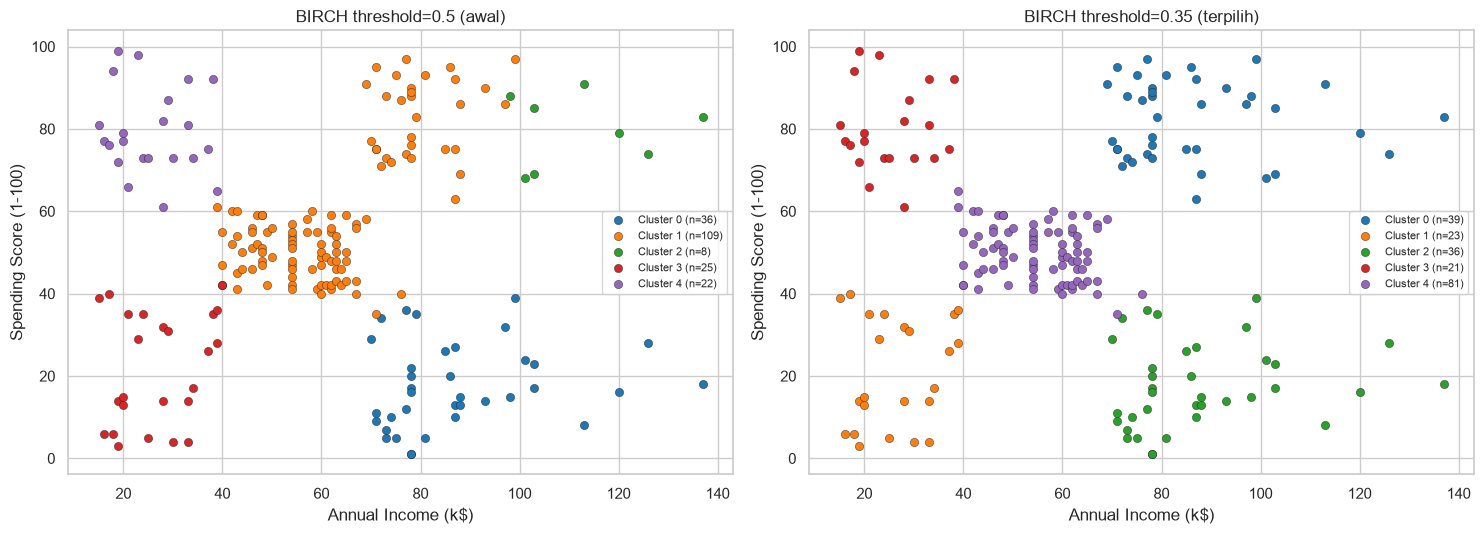

In [52]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.
def safe_silhouette(Xd, labels):
    k = len(np.unique(labels))
    return silhouette_score(Xd, labels) if 1 < k < len(labels) else np.nan

rows = []
for th in [0.2, 0.3, 0.35, 0.4, 0.5, 0.7, 1.0]:
    for nc in [5, None]:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")      # peringatan jika subcluster < n_clusters
            model = Birch(threshold=th, n_clusters=nc).fit(X_scaled)
        lab = model.labels_
        rows.append({"threshold": th,
                     "n_clusters (param)": "None" if nc is None else nc,
                     "n_subcluster": len(model.subcluster_centers_),
                     "n_cluster akhir": len(np.unique(lab)),
                     "ukuran cluster": sorted(np.bincount(lab).tolist(), reverse=True) if len(np.unique(lab)) <= 10 else "-",
                     "silhouette": safe_silhouette(X_scaled, lab)})
birch_grid = pd.DataFrame(rows)
display(birch_grid)

# Pilih threshold terbaik untuk n_clusters=5 berdasarkan silhouette
b5 = birch_grid[(birch_grid["n_clusters (param)"] == 5) & (birch_grid["n_cluster akhir"] == 5)]
BEST_TH = float(b5.sort_values("silhouette", ascending=False).iloc[0]["threshold"])
birch_best = Birch(threshold=BEST_TH, n_clusters=5).fit(X_scaled)
labels_birch_best = birch_best.labels_
print(f"Threshold BIRCH terpilih: {BEST_TH} (n_clusters=5), "
      f"silhouette={silhouette_score(X_scaled, labels_birch_best):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_clusters(labels_birch, "BIRCH threshold=0.5 (awal)", ax=axes[0])
plot_clusters(labels_birch_best, f"BIRCH threshold={BEST_TH} (terpilih)", ax=axes[1])
plt.tight_layout()
plt.show()

### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar? **Semakin besar nilai threshold, semakin banyak titik yang dapat ditampung dalam satu subcluster sehingga jumlah cluster semakin berkurang**
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama? **DBSCAN dapat menandai titik yang berada di daerah renggang sebagai noise (-1), sedangkan BIRCH selalu memasukkan setiap titik ke dalam salah satu cluster terdekat**
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan? **Ya, ketika n_clusters=None, jumlah cluster mengikuti jumlah subcluster yang terbentuk, sedangkan n_clusters=5 menghasilkan 5 cluster melalui proses penggabungan subcluster**

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [53]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.
gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=RANDOM_STATE)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)
print("EM konvergen:", gmm.converged_, "| jumlah iterasi EM:", gmm.n_iter_)
print("Bobot tiap komponen (pi_k):", np.round(gmm.weights_, 3))

EM konvergen: True | jumlah iterasi EM: 5
Bobot tiap komponen (pi_k): [0.413 0.197 0.104 0.166 0.121]


In [54]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.
print("Jumlah anggota per cluster GMM:")
print(pd.Series(labels_gmm).value_counts().sort_index())

proba = gmm.predict_proba(X_scaled)
proba_df = pd.DataFrame(proba, columns=[f"P(cluster {k})" for k in range(gmm.n_components)])
proba_df["max_proba"] = proba_df.max(axis=1)
proba_df["label"] = labels_gmm
print("\nContoh probabilitas keanggotaan (5 baris pertama):")
display(proba_df.head())

uncertain = proba_df["max_proba"] < 0.8
print(f"Titik dengan probabilitas maksimum < 0.8: {uncertain.sum()}")
print(f"Titik dengan probabilitas maksimum < 0.6: {(proba_df['max_proba'] < 0.6).sum()}")
print("\nTitik paling tidak pasti:")
display(pd.concat([X, proba_df], axis=1).sort_values("max_proba").head(8))

Jumlah anggota per cluster GMM:
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

Contoh probabilitas keanggotaan (5 baris pertama):


,P(cluster 0),P(cluster 1),P(cluster 2),P(cluster 3),P(cluster 4),max_proba,label
0,0.000,0.000,0.001,0.000,0.999,0.999,4
1,0.000,0.000,1.000,0.000,0.000,1.000,2
2,0.000,0.000,0.000,0.000,1.000,1.000,4
3,0.000,0.000,1.000,0.000,0.000,1.000,2
4,0.000,0.000,0.002,0.000,0.998,0.998,4


Titik dengan probabilitas maksimum < 0.8: 6
Titik dengan probabilitas maksimum < 0.6: 1

Titik paling tidak pasti:


,Annual Income (k$),Spending Score (1-100),P(cluster 0),P(cluster 1),P(cluster 2),P(cluster 3),P(cluster 4),max_proba,label
124,70,29,0.497,0.000,0.000,0.503,0.000,0.503,3
48,40,42,0.611,0.000,0.000,0.000,0.388,0.611,0
49,40,42,0.611,0.000,0.000,0.000,0.388,0.611,0
27,28,61,0.279,0.000,0.675,0.000,0.046,0.675,2
160,79,35,0.772,0.000,0.000,0.228,0.000,0.772,0
55,43,41,0.796,0.000,0.000,0.000,0.204,0.796,0
45,39,65,0.822,0.007,0.157,0.000,0.014,0.822,0
47,40,47,0.891,0.000,0.001,0.000,0.108,0.891,0


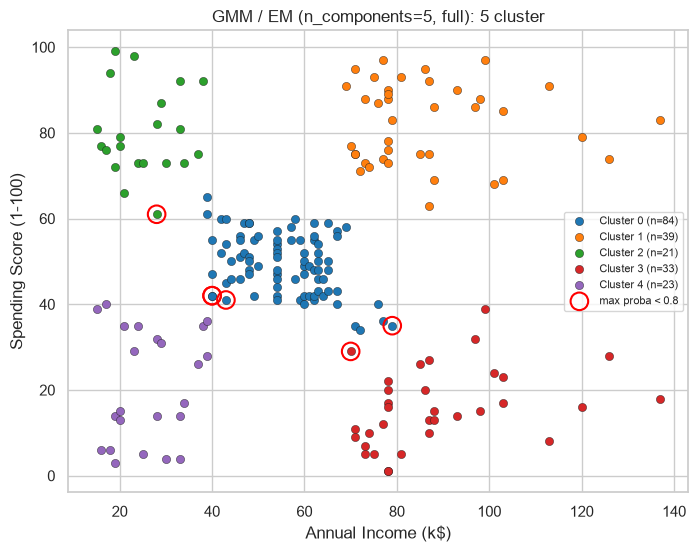

In [55]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.
ax = plot_clusters(labels_gmm, "GMM / EM (n_components=5, full): 5 cluster")
# Tandai titik yang keanggotaannya tidak pasti (max proba < 0.8)
ax.scatter(X.loc[uncertain, INCOME], X.loc[uncertain, SPEND], s=160, facecolors="none",
           edgecolors="red", linewidth=1.5, label="max proba < 0.8")
ax.legend(fontsize=8)
plt.show()

,n_components,silhouette,BIC,AIC
0,2,0.379,1153.905,1117.623
1,3,0.430,1151.718,1095.647
2,4,0.413,1103.790,1027.929
3,5,0.554,1058.652,963.001
4,6,0.517,1074.683,959.242
5,7,0.509,1087.329,952.098
6,8,0.430,1102.371,947.350


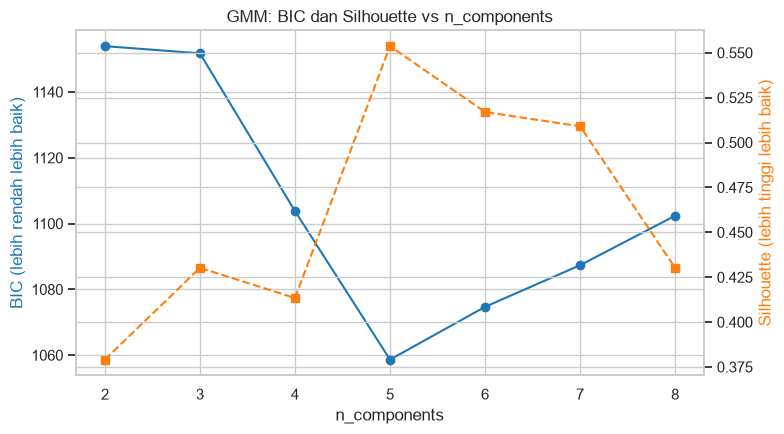

n_components dengan BIC terendah      : 5
n_components dengan Silhouette tertinggi: 5


,covariance_type,BIC,silhouette
0,full,1058.652,0.554
1,tied,1058.924,0.552
2,diag,1041.676,0.553
3,spherical,1047.033,0.554


In [56]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.
rows = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type="full", random_state=RANDOM_STATE).fit(X_scaled)
    lab = g.predict(X_scaled)
    rows.append({"n_components": k,
                 "silhouette": safe_silhouette(X_scaled, lab),
                 "BIC": g.bic(X_scaled),
                 "AIC": g.aic(X_scaled)})
gmm_grid = pd.DataFrame(rows)
display(gmm_grid)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(gmm_grid["n_components"], gmm_grid["BIC"], "o-", color="tab:blue", label="BIC")
ax1.set_xlabel("n_components"); ax1.set_ylabel("BIC (lebih rendah lebih baik)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(gmm_grid["n_components"], gmm_grid["silhouette"], "s--", color="tab:orange", label="Silhouette")
ax2.set_ylabel("Silhouette (lebih tinggi lebih baik)", color="tab:orange")
plt.title("GMM: BIC dan Silhouette vs n_components")
fig.tight_layout()
plt.show()

best_bic_k = int(gmm_grid.loc[gmm_grid["BIC"].idxmin(), "n_components"])
best_sil_k = int(gmm_grid.loc[gmm_grid["silhouette"].idxmax(), "n_components"])
print(f"n_components dengan BIC terendah      : {best_bic_k}")
print(f"n_components dengan Silhouette tertinggi: {best_sil_k}")

# (Tambahan) pengaruh covariance_type pada n_components=5
cov_rows = []
for cov in ["full", "tied", "diag", "spherical"]:
    g = GaussianMixture(n_components=5, covariance_type=cov, random_state=RANDOM_STATE).fit(X_scaled)
    cov_rows.append({"covariance_type": cov, "BIC": g.bic(X_scaled),
                     "silhouette": safe_silhouette(X_scaled, g.predict(X_scaled))})
display(pd.DataFrame(cov_rows))


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM? **Probabilitas keanggotaan menunjukkan seberapa besar kemungkinan suatu pelanggan termasuk ke dalam masing-masing komponen Gaussian. GMM menggunakan soft clustering, sehingga setiap pelanggan memiliki probabilitas keanggotaan pada seluruh cluster dengan total probabilitas sebesar 1**
- Apa yang terjadi ketika `n_components` diubah? **Jumlah komponen memengaruhi pembagian cluster. Pada 2–4 komponen, beberapa kelompok pelanggan tergabung, sedangkan pada 5 komponen diperoleh hasil terbaik dengan silhouette ±0,554 dan BIC ±1058,7. Penambahan komponen di atas 5 justru meningkatkan BIC dan menurunkan silhouette**
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih? **EM membutuhkan jumlah komponen yang tetap untuk mengestimasi parameter setiap distribusi Gaussian, yaitu bobot, mean, dan kovarians**
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah? **Ya, pada eksperimen ini model dengan n_components=5 memiliki silhouette tertinggi (±0,554) sekaligus BIC terendah (±1058,7), sehingga keduanya menunjukkan bahwa 5 cluster merupakan pilihan terbaik**

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [57]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.
def evaluate_clustering(X_data, labels, model_name, exclude_noise=False):
    labels = np.asarray(labels)
    n_noise = int((labels == -1).sum())
    if exclude_noise:
        mask = labels != -1
        X_eval, lab_eval = X_data[mask], labels[mask]
    else:
        X_eval, lab_eval = X_data, labels
    n_clusters = len(np.unique(lab_eval))
    valid = 2 <= n_clusters < len(lab_eval)
    return {
        "model": model_name,
        "n_clusters": n_clusters,
        "n_noise": n_noise if exclude_noise else "N/A",
        "n_dievaluasi": len(lab_eval),
        "silhouette": silhouette_score(X_eval, lab_eval) if valid else np.nan,
        "davies_bouldin": davies_bouldin_score(X_eval, lab_eval) if valid else np.nan,
        "calinski_harabasz": calinski_harabasz_score(X_eval, lab_eval) if valid else np.nan,
    }

In [58]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.
gmm_best = GaussianMixture(n_components=best_bic_k, covariance_type="full",
                           random_state=RANDOM_STATE).fit(X_scaled)
labels_gmm_best = gmm_best.predict(X_scaled)

results = pd.DataFrame([
    evaluate_clustering(X_scaled, labels_dbscan_best,
                        f"DBSCAN (eps={BEST_EPS}, min_samples={BEST_MS})", exclude_noise=True),
    evaluate_clustering(X_scaled, labels_birch_best,
                        f"BIRCH (threshold={BEST_TH}, n_clusters=5)"),
    evaluate_clustering(X_scaled, labels_gmm_best,
                        f"GMM/EM (n_components={best_bic_k}, full)"),
])
display(results)

# Pembanding yang adil: DBSCAN dengan noise diperlakukan sebagai satu "cluster" tambahan,
# sehingga semua 200 titik ikut dinilai seperti pada BIRCH dan GMM.
fair = evaluate_clustering(X_scaled, labels_dbscan_best, "DBSCAN (noise dihitung sbg grup)")
print("DBSCAN bila noise ikut dinilai (200 titik):")
display(pd.DataFrame([fair]))

,model,n_clusters,n_noise,n_dievaluasi,silhouette,davies_bouldin,calinski_harabasz
0,"DBSCAN (eps=0.4, min_samples=8)",5,25,175,0.549,0.501,222.065
1,"BIRCH (threshold=0.35, n_clusters=5)",5,N/A,200,0.555,0.570,248.033
2,"GMM/EM (n_components=5, full)",5,N/A,200,0.554,0.576,244.940


DBSCAN bila noise ikut dinilai (200 titik):


,model,n_clusters,n_noise,n_dievaluasi,silhouette,davies_bouldin,calinski_harabasz
0,DBSCAN (noise dihitung sbg grup),6,N/A,200,0.415,1.651,69.149


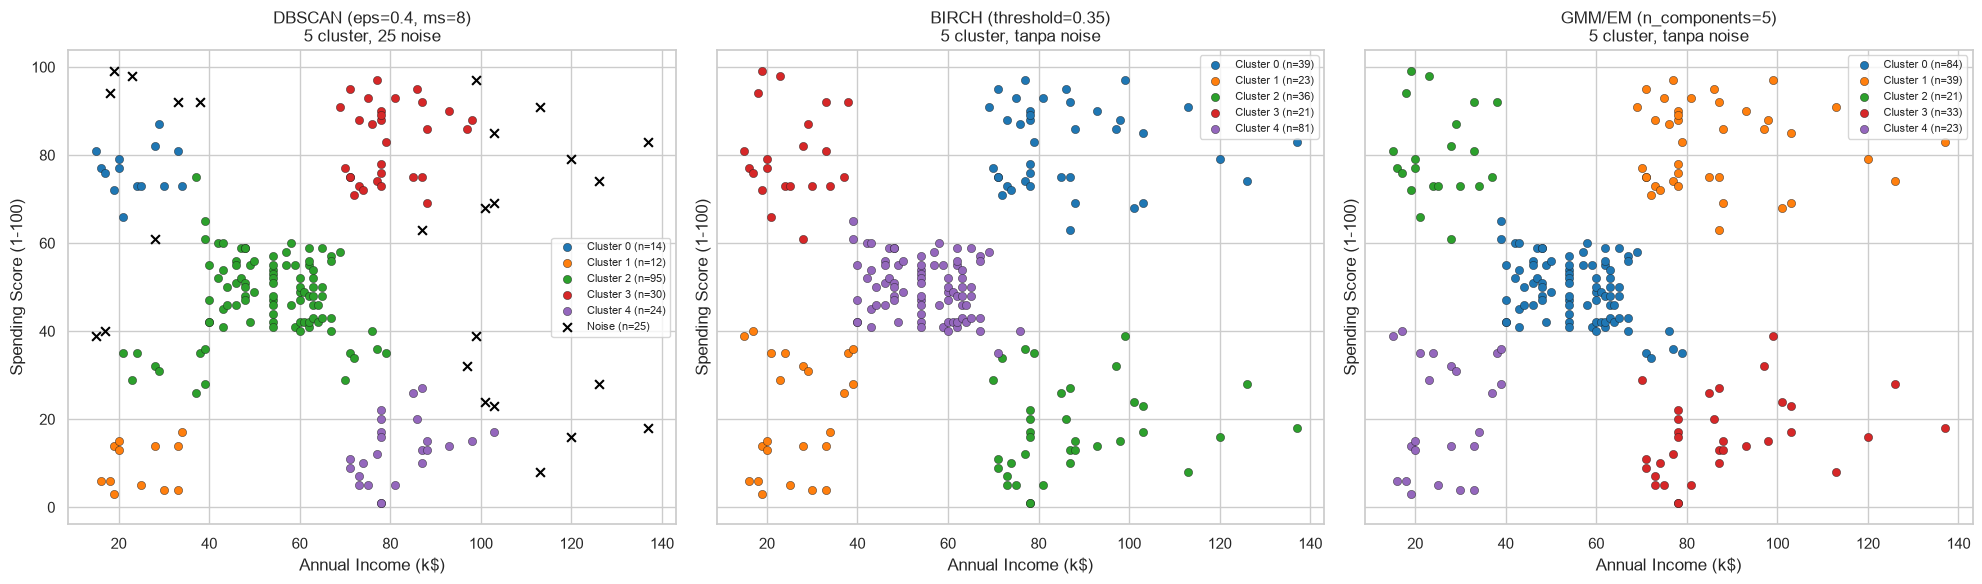

In [59]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
n_cl_db, n_noise_db = ringkas_dbscan(labels_dbscan_best)
plot_clusters(labels_dbscan_best,
              f"DBSCAN (eps={BEST_EPS}, ms={BEST_MS})\n{n_cl_db} cluster, {n_noise_db} noise", ax=axes[0])
plot_clusters(labels_birch_best,
              f"BIRCH (threshold={BEST_TH})\n{len(np.unique(labels_birch_best))} cluster, tanpa noise", ax=axes[1])
plot_clusters(labels_gmm_best,
              f"GMM/EM (n_components={best_bic_k})\n{len(np.unique(labels_gmm_best))} cluster, tanpa noise", ax=axes[2])
plt.tight_layout()
plt.show()

In [60]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.
def nama_segmen(inc, spd):
    """Nama deskriptif berdasarkan median pendapatan dan spending score."""
    if inc < 40 and spd < 40:   return "Hemat - pendapatan rendah"
    if inc < 40 and spd >= 60:  return "Boros - pendapatan rendah (impulsif)"
    if inc >= 70 and spd < 40:  return "Hati-hati - pendapatan tinggi"
    if inc >= 70 and spd >= 60: return "Target utama - pendapatan & spending tinggi"
    return "Standar - menengah"

def profil(labels, nama_model):
    d = X.assign(cluster=labels)
    p = d.groupby("cluster").agg(
        jumlah=(INCOME, "size"),
        income_median=(INCOME, "median"), income_mean=(INCOME, "mean"),
        spending_median=(SPEND, "median"), spending_mean=(SPEND, "mean"))
    p["segmen"] = [("NOISE" if c == -1 else nama_segmen(r.income_median, r.spending_median))
                   for c, r in p.iterrows()]
    print(f"Profil cluster: {nama_model}")
    display(p.round(1))
    return p

prof_db = profil(labels_dbscan_best, "DBSCAN")
prof_bi = profil(labels_birch_best, "BIRCH")
prof_gm = profil(labels_gmm_best, "GMM/EM")

# Analisis titik noise DBSCAN secara terpisah
noise = X[labels_dbscan_best == -1]
print(f"Titik noise DBSCAN: {len(noise)}")
display(noise.describe().round(1))
print("Segmen GMM dari titik-titik noise tersebut:")
print(pd.Series(labels_gmm_best[labels_dbscan_best == -1])
      .map(prof_gm["segmen"]).value_counts())

Profil cluster: DBSCAN


,jumlah,income_median,income_mean,spending_median,spending_mean,segmen
cluster,,,,,,
-1,25,101.000,83.000,68.000,60.500,NOISE
0,14,22.500,23.600,76.500,76.400,Boros - pendapatan rendah (impulsif)
1,12,22.500,24.600,9.500,9.600,Hemat - pendapatan rendah
2,95,54.000,53.300,48.000,47.800,Standar - menengah
3,30,78.000,79.500,86.000,83.100,Target utama - pendapatan & spending tinggi
4,24,78.000,81.900,13.000,13.000,Hati-hati - pendapatan tinggi


Profil cluster: BIRCH


,jumlah,income_median,income_mean,spending_median,spending_mean,segmen
cluster,,,,,,
0,39,79.000,86.500,83.000,82.100,Target utama - pendapatan & spending tinggi
1,23,25.000,26.300,17.000,20.900,Hemat - pendapatan rendah
2,36,83.000,87.800,16.000,17.600,Hati-hati - pendapatan tinggi
3,21,24.000,25.100,77.000,80.000,Boros - pendapatan rendah (impulsif)
4,81,54.000,54.900,50.000,49.900,Standar - menengah


Profil cluster: GMM/EM


,jumlah,income_median,income_mean,spending_median,spending_mean,segmen
cluster,,,,,,
0,84,55.500,55.600,49.500,49.400,Standar - menengah
1,39,79.000,86.500,83.000,82.100,Target utama - pendapatan & spending tinggi
2,21,24.000,25.100,77.000,80.000,Boros - pendapatan rendah (impulsif)
3,33,86.000,88.800,15.000,16.000,Hati-hati - pendapatan tinggi
4,23,25.000,26.300,17.000,20.900,Hemat - pendapatan rendah


Titik noise DBSCAN: 25


,Annual Income (k$),Spending Score (1-100)
count,25.000,25.000
mean,83.000,60.500
std,43.300,30.600
min,15.000,8.000
25%,33.000,32.000
50%,101.000,68.000
75%,113.000,91.000
max,137.000,99.000


Segmen GMM dari titik-titik noise tersebut:
Target utama - pendapatan & spending tinggi    9
Hati-hati - pendapatan tinggi                  8
Boros - pendapatan rendah (impulsif)           6
Hemat - pendapatan rendah                      2
Name: count, dtype: int64


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak, jumlah cluster muncul dari `eps` dan `min_samples` (pada data ini 1–13 cluster tergantung parameter) | Opsional; `n_clusters=None` memakai subcluster mentah, `n_clusters=5` menambah tahap global clustering | Ya, `n_components` wajib ditentukan; dipilih lewat BIC (terbaik = 5) |
| Dapat memberi label noise secara eksplisit? | Ya, label `-1` (25 titik / 12,5% pada model terpilih) | Tidak, semua titik dimasukkan ke cluster | Tidak, tetapi probabilitas keanggotaan rendah menandai titik yang tidak pasti (6 titik < 0,8) |
| Parameter yang paling memengaruhi hasil | `eps` (sangat sensitif: 0,5 → 0,6 berubah dari 2 cluster ke 1 cluster), lalu `min_samples` | `threshold` (0,3 vs 0,35 menghasilkan silhouette 0,478 vs 0,555) dan `n_clusters` | `n_components`, lalu `covariance_type`; `random_state` memengaruhi inisialisasi |
| Bentuk cluster yang dapat dimodelkan | Bentuk sembarang (non-konveks), asalkan kepadatannya mirip | Cenderung bulat/konveks (berbasis radius & centroid) | Elips dengan orientasi dan ukuran berbeda (`full` covariance) |
| Kelebihan | Tidak perlu jumlah cluster; mendeteksi outlier; bisa menangkap bentuk tidak beraturan | Cepat & hemat memori untuk data besar (satu kali scan, CF-tree); mendukung incremental learning | Soft clustering dengan probabilitas; fleksibel untuk cluster elips; ada kriteria statistik (BIC/AIC) untuk memilih jumlah cluster |
| Kekurangan | Sulit memilih `eps`; gagal bila kepadatan cluster berbeda (kelompok pendapatan tinggi yang renggang banyak menjadi noise) | Sensitif terhadap `threshold` dan urutan data; tidak menangani outlier; kurang cocok untuk bentuk tidak bulat | Harus menentukan jumlah komponen; asumsi Gaussian; bisa terjebak lokal optimum; lebih berat secara komputasi |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

---
**Jawab:**

1. Ketiga algoritma menggunakan jarak atau varians dalam proses clustering. DBSCAN menggunakan radius eps, BIRCH menggunakan radius `threshold`, sedangkan GMM memperhitungkan mean dan kovarians. Tanpa scaling, fitur dengan rentang nilai lebih besar, seperti pendapatan (15–137), akan lebih dominan dibandingkan spending score (1–99). Setelah menggunakan `StandardScaler`, kedua fitur memiliki rata-rata 0 dan standar deviasi 1 sehingga kontribusinya dalam proses clustering menjadi lebih seimbang.

2. Semakin besar nilai `eps`, semakin banyak titik yang dapat saling terhubung sehingga jumlah noise berkurang dan beberapa cluster dapat bergabung. Pada `min_samples=5`, jumlah noise turun dari 77 menjadi 5, sedangkan jumlah cluster berkurang dari 7 menjadi 1 ketika eps meningkat dari 0,2 menjadi 0,6. Sebaliknya, semakin besar `min_samples`, semakin ketat syarat kepadatan sehingga jumlah noise meningkat. Model dengan `eps=0.4` dan `min_samples=8` dipilih karena menghasilkan 5 cluster dengan 25 noise.

3. Semakin besar nilai `threshold`, semakin banyak titik yang dapat dimasukkan ke dalam satu subcluster sehingga jumlah subcluster semakin sedikit. Jumlah subcluster berkurang dari 39 pada threshold 0,2 menjadi 4 pada threshold 1,0. Jika jumlah subcluster lebih sedikit daripada `n_clusters` yang ditentukan, BIRCH tidak dapat menghasilkan jumlah cluster sesuai permintaan. Pada eksperimen ini, `threshold=0.35` dan `n_clusters=5` memberikan hasil terbaik dengan silhouette ±0,555. Sementara itu, `n_clusters` menentukan jumlah cluster akhir setelah subcluster digabungkan. Jika tidak ditentukan, jumlah cluster mengikuti jumlah subcluster yang terbentuk.

4. Probabilitas keanggotaan adalah posterior P(komponen k | x<sub>i</sub>). EM bekerja iteratif: E-step menghitung probabilitas (responsibility) ini untuk setiap titik berdasarkan parameter saat ini. M-step memperbarui bobot π<sub>k</sub>, mean μ<sub>k</sub>, dan kovarians Σ<sub>k</sub> sebagai rata-rata berbobot dengan responsibility tersebut sebagai bobot. Kedua langkah diulang hingga log-likelihood konvergen (model ini konvergen dalam beberapa iterasi, lihat `gmm.n_iter_`). Pada hasil kita, 194 dari 200 pelanggan memiliki probabilitas maksimum ≥ 0,8, sedangkan 6 pelanggan di perbatasan antar segmen memiliki keanggotaan yang lebih ambigu.

5. GMM/EM dengan 5 komponen dan BIRCH dengan threshold=0.35 merupakan model yang paling mudah diinterpretasikan karena keduanya berhasil membagi seluruh 200 pelanggan ke dalam lima kelompok yang sesuai dengan pola pada scatter plot. GMM sedikit lebih unggul karena memberikan informasi probabilitas keanggotaan sehingga pelanggan yang berada di antara dua kelompok dapat diidentifikasi. Sementara itu, DBSCAN kurang cocok sebagai metode segmentasi utama karena terdapat 25 pelanggan yang dikategorikan sebagai noise dan tidak masuk ke dalam cluster mana pun.

6. Tidak sepenuhnya, dari tabel evaluasi:
- Silhouette tertinggi: BIRCH (±0,555), sangat tipis di atas GMM (±0,554) dan DBSCAN (±0,549).
- Davies-Bouldin terendah (terbaik): DBSCAN (±0,501), dibanding BIRCH ±0,570 dan GMM ±0,576.
- Calinski-Harabasz tertinggi: BIRCH (±248), lalu GMM (±245), DBSCAN paling rendah (±222).

Perbedaan tersebut terjadi karena setiap metrik memiliki cara penilaian yang berbeda. DBSCAN hanya dievaluasi menggunakan 175 titik non-noise, sehingga kelompok yang tersisa cenderung lebih kompak dan menghasilkan Davies-Bouldin Index yang lebih rendah. Namun, jika seluruh titik termasuk noise ikut dievaluasi, kualitas clustering DBSCAN menurun cukup jauh. Sementara itu, hasil BIRCH dan GMM hampir sama sehingga perbedaan nilai metrik keduanya relatif kecil. Oleh karena itu, pemilihan algoritma tidak cukup hanya berdasarkan satu metrik evaluasi.

7. Karakteristik cluster berdasarkan median pendapatan dan spending score

| Segmen | Jumlah (GMM) | Median Income (k$) | Median Spending | Interpretasi |
|---|---|---|---|---|
| Standar / menengah | 84 | ±55,5 | ±49,5 | Segmen terbesar, pendapatan dan pengeluaran rata-rata |
| Target utama (pendapatan & spending tinggi) | 39 | ±79 | ±83 | Pelanggan paling bernilai; cocok untuk program loyalitas/premium |
| Hati-hati / hemat (pendapatan tinggi, spending rendah) | 33 | ±86 | ±15 | Mampu membeli tetapi jarang belanja; peluang untuk dikonversi |
| Impulsif / boros (pendapatan rendah, spending tinggi) | 21 | ±24 | ±77 | Belanja tinggi meski pendapatan rendah; responsif terhadap promo |
| Hemat (pendapatan & spending rendah) | 23 | ±25 | ±17 | Sensitif harga; prioritas pemasaran rendah |

DBSCAN juga menemukan lima kelompok yang serupa, tetapi terdapat 25 pelanggan yang dikategorikan sebagai noise. Sebagian besar berasal dari kelompok berpendapatan tinggi, yaitu 17 pelanggan dari total 25 noise. Hal ini menunjukkan bahwa DBSCAN lebih sulit mengenali kelompok yang memiliki kepadatan lebih rendah.

8. Keterbatasan eksperimen
- Penggunaan hanya dua fitur, yaitu pendapatan dan spending score, belum cukup untuk menggambarkan karakteristik pelanggan secara keseluruhan. Faktor lain seperti usia, gender, frekuensi kunjungan, dan nilai transaksi belum diperhitungkan.
- Spending Score merupakan skor yang diberikan oleh pihak mall, tetapi cara perhitungannya tidak dijelaskan sehingga interpretasinya masih terbatas.
- Jumlah data yang hanya 200 pelanggan membuat hasil clustering, terutama pada kelompok yang beranggotakan sedikit orang, berpotensi kurang stabil dan sensitif terhadap titik ekstrem.
- Dataset memiliki pola kelompok yang cukup jelas sehingga hasil eksperimen belum tentu sama jika diterapkan pada data transaksi nyata yang lebih kompleks.
- Tidak adanya label atau ground truth membuat kualitas clustering hanya dapat dinilai melalui metrik internal dan visualisasi, bukan berdasarkan kecocokan dengan kelompok pelanggan yang sebenarnya.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

---

**Kesimpulan**

1. Berdasarkan hasil eksperimen, EM/GMM dengan 5 komponen menjadi algoritma yang paling baik untuk segmentasi pelanggan mall. Model ini berhasil membagi seluruh 200 pelanggan ke dalam 5 kelompok dengan silhouette tertinggi (±0,554) dan BIC terendah (±1058,7). Selain itu, GMM juga memberikan probabilitas keanggotaan sehingga dapat diketahui bahwa terdapat 6 pelanggan yang memiliki kemungkinan keanggotaan kurang dari 0,8 atau berada di antara beberapa kelompok. BIRCH juga memberikan hasil yang hampir sama baiknya, sedangkan DBSCAN lebih cocok digunakan untuk mendeteksi pelanggan yang memiliki pola berbeda karena beberapa pelanggan justru dikategorikan sebagai noise.

2. Parameter yang digunakan pada DBSCAN adalah eps=0.4 dan min_samples=8 karena menghasilkan 5 cluster dengan 25 noise (12,5%) dan silhouette ±0,549. Pada BIRCH digunakan threshold=0.35 dan n_clusters=5 karena menghasilkan 5 cluster dengan silhouette ±0,555 dan pembagian anggota yang cukup seimbang. Sementara itu, GMM menggunakan n_components=5 dan covariance_type='full' karena menghasilkan silhouette tertinggi (±0,554) dan BIC terendah (±1058,7) dibandingkan jumlah komponen lainnya.

3. DBSCAN mengelompokkan data berdasarkan kepadatan dan dapat memisahkan titik yang dianggap sebagai noise. BIRCH membentuk kelompok berdasarkan ringkasan data dalam CF-tree dan tetap memasukkan seluruh titik ke dalam cluster. Sementara itu, EM/GMM menggunakan pendekatan probabilistik yang memungkinkan setiap pelanggan memiliki probabilitas keanggotaan pada beberapa cluster. Berdasarkan eksperimen, terlihat bahwa ketiga algoritma memiliki cara yang berbeda dalam mengelompokkan pelanggan, meskipun hasil BIRCH dan GMM cukup mirip.

4. Eksperimen selanjutnya dapat dilakukan dengan menambahkan fitur Age dan Gender untuk melihat apakah karakteristik pelanggan lainnya memengaruhi hasil segmentasi. Selain itu, dapat dicoba algoritma HDBSCAN atau OPTICS untuk menangani kelompok dengan kepadatan berbeda, serta membandingkan hasilnya dengan K-Means dan Agglomerative Clustering. Penggunaan scaler lain seperti MinMaxScaler dan RobustScaler juga dapat diuji untuk melihat pengaruhnya terhadap hasil clustering. Terakhir, segmentasi dapat dikembangkan menggunakan data transaksi nyata agar setiap kelompok pelanggan dapat dianalisis lebih lanjut berdasarkan perilaku belanjanya.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)